# Examen Unidad 2 — Fundamentos de Ciencia de Datos
**Caso A: Arquitectura de Software (Monolito vs. Microservicios)**

- Variable cuantitativa (Y): latencia de respuesta HTTP (ms)
- Variable cualitativa (X): arquitectura (Monolito vs. Microservicios)
- Muestra: 250 observaciones por grupo (N = 500)
- Objetivo: determinar si la sobrecarga de red incrementa la latencia en microservicios

In [1]:
import platform
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from scipy import stats

np.random.seed(42)
sns.set_theme(style="whitegrid")


def get_base_dir():
    kaggle_dir = Path("/kaggle/working")
    return kaggle_dir if kaggle_dir.exists() else Path.cwd().parent


BASE = get_base_dir()
DATA_DIR = BASE / "data"
FIG_DIR = BASE / "docs" / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__}")
print(f"Directorio base: {BASE}")

Python 3.14.7 | numpy 2.5.4 | scipy 1.18.1
Directorio base: C:\Proyectos\examen_fcd_u2


## Bloque 1 — Estadística descriptiva y limpieza

- Generación sintética justificada (distribuciones gamma, cola derecha)
- Verificación de tipos y valores ausentes
- Detección de atípicos con criterio 1.5 x IQR
- Estadísticos por grupo: media, mediana, desviación, varianza, asimetría, curtosis
- Histogramas + KDE y boxplots comparativos

In [2]:
def generar_dataset(n=250):
    lat_monolito = np.random.gamma(shape=2.5, scale=35, size=n) + 40
    lat_microserv = np.random.gamma(shape=2.2, scale=40, size=n) + 45
    return pd.DataFrame({
        "latencia_ms": np.concatenate([lat_monolito, lat_microserv]),
        "grupo": ["Monolito"] * n + ["Microservicios"] * n,
    })


df = generar_dataset()
df.to_csv(DATA_DIR / "dataset_caso_a.csv", index=False)
print(f"Dataset original: {len(df)} registros -> data/dataset_caso_a.csv")
df.groupby("grupo")["latencia_ms"].describe().round(2)

Dataset original: 500 registros -> data/dataset_caso_a.csv


,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
Microservicios,250.0,129.36,55.50,52.29,89.96,116.48,158.17,367.08
Monolito,250.0,129.63,53.23,41.43,90.38,119.20,154.48,326.69


In [3]:
df = pd.read_csv(DATA_DIR / "dataset_caso_a.csv")
print("Tipos de datos:")
print(df.dtypes)
print(f"\nValores ausentes: {int(df.isna().sum().sum())}")
print(f"Duplicados: {int(df.duplicated().sum())}")
df.head()

Tipos de datos:
latencia_ms    float64
grupo              str
dtype: object

Valores ausentes: 0
Duplicados: 0


,latencia_ms,grupo
0,144.409738,Monolito
1,108.930854,Monolito
2,104.398430,Monolito
3,104.399188,Monolito
4,229.756236,Monolito


In [4]:
def depurar_outliers(datos, factor=1.5):
    dentro = pd.Series(True, index=datos.index)
    for grupo, indices in datos.groupby("grupo").groups.items():
        serie = datos.loc[indices, "latencia_ms"]
        q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
        iqr = q3 - q1
        dentro[indices] = serie.between(q1 - factor * iqr, q3 + factor * iqr)
    return datos[dentro]


df_depurado = depurar_outliers(df)
eliminados = len(df) - len(df_depurado)
print(f"Atipicos removidos (1.5xIQR): {eliminados} de {len(df)}")
print(df_depurado.groupby("grupo").size().rename("n_final"))
df_depurado.to_csv(DATA_DIR / "dataset_caso_a_depurado.csv", index=False)

Atipicos removidos (1.5xIQR): 17 de 500
grupo
Microservicios    243
Monolito          240
Name: n_final, dtype: int64


In [5]:
def resumen_descriptivo(datos):
    return (
        datos.groupby("grupo")["latencia_ms"]
        .agg(media="mean", mediana="median", desv_estandar="std", varianza="var",
             asimetria=stats.skew, curtosis=lambda s: stats.kurtosis(s))
        .round(3)
    )


tabla_descriptiva = resumen_descriptivo(df_depurado)
tabla_descriptiva

,media,mediana,desv_estandar,varianza,asimetria,curtosis
grupo,,,,,,
Microservicios,124.614,113.969,48.204,2323.634,0.770,-0.094
Monolito,123.200,117.012,43.529,1894.787,0.616,-0.159


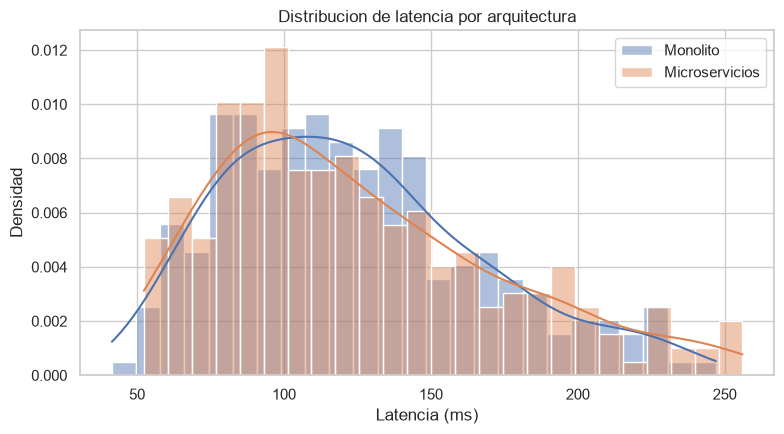

In [6]:
def graficar_histogramas(datos):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for grupo in datos["grupo"].unique():
        serie = datos.loc[datos["grupo"] == grupo, "latencia_ms"]
        sns.histplot(serie, bins=25, stat="density", kde=True, ax=ax, alpha=0.45, label=grupo)
    ax.set(xlabel="Latencia (ms)", ylabel="Densidad", title="Distribucion de latencia por arquitectura")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "histogramas_kde.png", dpi=150)
    plt.show()


graficar_histogramas(df_depurado)

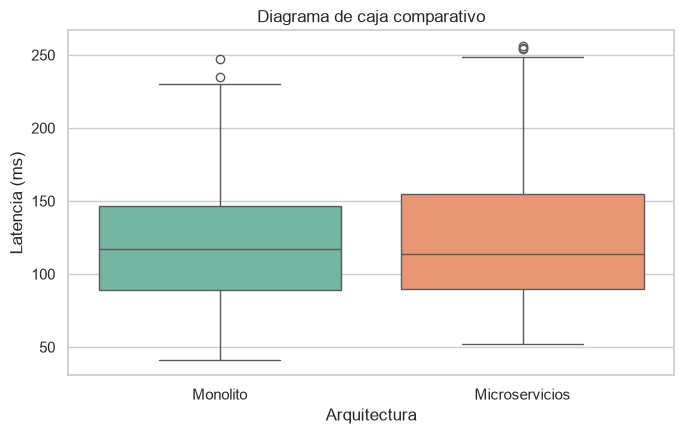

In [7]:
def graficar_boxplots(datos):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.boxplot(data=datos, x="grupo", y="latencia_ms", hue="grupo", ax=ax,
                palette="Set2", legend=False)
    ax.set(xlabel="Arquitectura", ylabel="Latencia (ms)", title="Diagrama de caja comparativo")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "boxplots.png", dpi=150)
    plt.show()


graficar_boxplots(df_depurado)

**Interpretacion (dispersion y sesgo)**

- Asimetria positiva en ambos grupos (0.62 Monolito, 0.77 Microservicios): cola derecha tipica de latencias de red.
- Curtosis cercana a 0 (-0.16 y -0.09): colas menos pesadas que la normal.
- Microservicios con mayor dispersion (s = 48.20 vs 43.53 ms); mediana < media por el sesgo positivo.

## Bloque 2 — Teorema Central del Limite

- Muestra global: N >= 400
- Remuestreo con reemplazo: k = 1000 medias para n = 5, 15, 30, 60
- Cuadricula 2x2 de distribuciones de medias muestrales
- Error estandar empirico vs teorico: sigma_barra_x = s / sqrt(n)

In [8]:
def medias_bootstrap(serie, n, k=1000):
    muestras = np.random.choice(serie, size=(k, n), replace=True)
    return muestras.mean(axis=1)


muestra_global = df_depurado["latencia_ms"]
print(f"Tamano de la muestra global: {len(muestra_global)}")
print(f"Media global: {muestra_global.mean():.3f} ms | s global: {muestra_global.std(ddof=1):.3f} ms")

Tamano de la muestra global: 483
Media global: 123.911 ms | s global: 45.898 ms


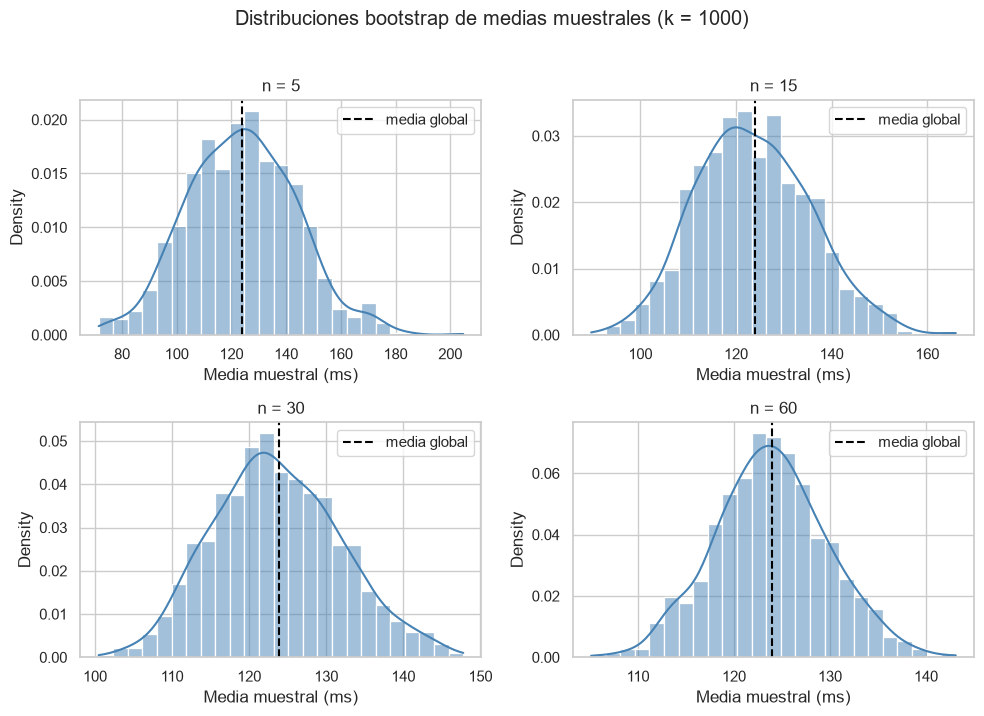

In [9]:
def graficar_tcl(medias_por_n):
    fig, ejes = plt.subplots(2, 2, figsize=(10, 7))
    for n, ax in zip(medias_por_n, ejes.ravel()):
        sns.histplot(medias_por_n[n], bins=25, stat="density", kde=True, ax=ax, color="steelblue")
        ax.axvline(muestra_global.mean(), color="black", linestyle="--", label="media global")
        ax.set_title(f"n = {n}")
        ax.set_xlabel("Media muestral (ms)")
        ax.legend()
    fig.suptitle("Distribuciones bootstrap de medias muestrales (k = 1000)", y=1.02)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "tcl_grid.png", dpi=150, bbox_inches="tight")
    plt.show()


tamano = [5, 15, 30, 60]
medias_por_n = {n: medias_bootstrap(muestra_global, n) for n in tamano}
graficar_tcl(medias_por_n)

In [10]:
def tabla_error_estandar(medias_dict, serie_global):
    s_global = serie_global.std(ddof=1)
    filas = []
    for n, medias in medias_dict.items():
        se_empirico = medias.std(ddof=1)
        se_teorico = s_global / np.sqrt(n)
        filas.append({
            "n": n,
            "media_de_medias": medias.mean(),
            "se_empirico": se_empirico,
            "se_teorico": se_teorico,
            "diferencia_pct": 100 * abs(se_empirico - se_teorico) / se_teorico,
        })
    return pd.DataFrame(filas).round(4)


tabla_se = tabla_error_estandar(medias_por_n, muestra_global)
tabla_se

,n,media_de_medias,se_empirico,se_teorico,diferencia_pct
0,5,123.9183,19.8863,20.5264,3.1183
1,15,123.6154,11.9320,11.8509,0.6837
2,30,123.6579,8.2357,8.3799,1.7209
3,60,123.8824,5.8596,5.9255,1.1120


**Justificacion de la convergencia**

- El SE empirico difiere del teorico s/sqrt(n) entre 0.68% y 3.12% en los cuatro tamanos muestrales.
- A mayor n las medias se concentran y su distribucion tiende a la normal (TCL).

## Bloque 3 — Intervalos de confianza

- IC para la media general al 90%, 95% y 99% (t-Student: sigma desconocida, se estima con s)
- Prueba de Levene para homogeneidad de varianzas
- IC 95% para la diferencia de medias (pooled o Welch segun Levene)
- Verificacion de pertenencia de cero al intervalo

In [11]:
def intervalo_confianza(serie, confianza):
    n = len(serie)
    media = serie.mean()
    se = serie.std(ddof=1) / np.sqrt(n)
    t_crit = stats.t.ppf((1 + confianza) / 2, df=n - 1)
    return media - t_crit * se, media + t_crit * se, t_crit


def tabla_ic_general(serie):
    filas = []
    for conf in (0.90, 0.95, 0.99):
        li, ls, t_crit = intervalo_confianza(serie, conf)
        filas.append({"confianza": f"{conf:.0%}", "limite_inferior": li,
                      "limite_superior": ls, "t_critico": t_crit})
    return pd.DataFrame(filas).round(3)


tabla_ic = tabla_ic_general(muestra_global)
tabla_ic

,confianza,limite_inferior,limite_superior,t_critico
0,90%,120.470,127.353,1.648
1,95%,119.808,128.015,1.965
2,99%,118.511,129.312,2.586


In [12]:
serie_mono = df_depurado.loc[df_depurado["grupo"] == "Monolito", "latencia_ms"]
serie_micro = df_depurado.loc[df_depurado["grupo"] == "Microservicios", "latencia_ms"]

estadistico_levene, p_levene = stats.levene(serie_mono, serie_micro)
homogeneidad = p_levene >= 0.05
print(f"Levene: W = {estadistico_levene:.4f} | p-valor = {p_levene:.4f}")
print("Varianzas homogeneas -> varianzas combinadas" if homogeneidad else "Varianzas heterogeneas -> correccion de Welch")

Levene: W = 1.8419 | p-valor = 0.1754
Varianzas homogeneas -> varianzas combinadas


In [13]:
def ic_diferencia_medias(s1, s2, confianza=0.95, varianzas_homogeneas=True):
    n1, n2 = len(s1), len(s2)
    dif = s1.mean() - s2.mean()
    if varianzas_homogeneas:
        gl = n1 + n2 - 2
        sp2 = ((n1 - 1) * s1.var(ddof=1) + (n2 - 1) * s2.var(ddof=1)) / gl
        se = np.sqrt(sp2 * (1 / n1 + 1 / n2))
    else:
        v1, v2 = s1.var(ddof=1), s2.var(ddof=1)
        se = np.sqrt(v1 / n1 + v2 / n2)
        gl = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    t_crit = stats.t.ppf((1 + confianza) / 2, df=gl)
    return dif - t_crit * se, dif + t_crit * se, gl, dif


ic_lo, ic_hi, gl, dif = ic_diferencia_medias(serie_mono, serie_micro,
                                             varianzas_homogeneas=homogeneidad)
print(f"Diferencia de medias (Monolito - Microservicios): {dif:.3f} ms")
print(f"IC 95%: [{ic_lo:.3f}, {ic_hi:.3f}] ms | grados de libertad = {gl:.1f}")
print(f"Cero pertenece al intervalo: {bool(ic_lo <= 0 <= ic_hi)}")

Diferencia de medias (Monolito - Microservicios): -1.415 ms
IC 95%: [-9.630, 6.800] ms | grados de libertad = 481.0
Cero pertenece al intervalo: True


**Interpretacion de 0 en el IC**

- IC 95% para mu1 - mu2: [-9.63, 6.80] ms -> 0 pertenece al intervalo.
- No hay diferencia significativa entre arquitecturas al 95% de confianza.

## Bloque 4 — Teoria de decision (prueba de hipotesis)

- H0: mu_monolito = mu_microservicios (la arquitectura no afecta la latencia)
- H1: mu_monolito != mu_microservicios (diferencia bilateral)
- Nivel de significancia: alpha = 0.05
- Matriz de decision con costos de Error Tipo I y Tipo II
- Prueba t de Student para muestras independientes

In [14]:
def matriz_decision():
    return pd.DataFrame([
        {"hipotesis_verdadera": "H0 (sin diferencia)", "decision": "Rechazar H0",
         "resultado": "Error Tipo I (alpha)",
         "costo": "Migrar a microservicios sin beneficio medible: mayor complejidad operativa e infraestructura"},
        {"hipotesis_verdadera": "H0 (sin diferencia)", "decision": "No rechazar H0",
         "resultado": "Decision correcta (1-alpha)",
         "costo": "Se conserva el monolito con evidencia de ausencia de sobrecarga significativa"},
        {"hipotesis_verdadera": "H1 (con diferencia)", "decision": "Rechazar H0",
         "resultado": "Decision correcta (1-beta)",
         "costo": "Migracion justificada: se absorbe la sobrecarga planificando latencia"},
        {"hipotesis_verdadera": "H1 (con diferencia)", "decision": "No rechazar H0",
         "resultado": "Error Tipo II (beta)",
         "costo": "No migrar existiendo sobrecarga real: latencia evitable en produccion"},
    ])


print(matriz_decision().to_string(index=False))

hipotesis_verdadera       decision                   resultado                                                                                        costo
H0 (sin diferencia)    Rechazar H0        Error Tipo I (alpha) Migrar a microservicios sin beneficio medible: mayor complejidad operativa e infraestructura
H0 (sin diferencia) No rechazar H0 Decision correcta (1-alpha)                Se conserva el monolito con evidencia de ausencia de sobrecarga significativa
H1 (con diferencia)    Rechazar H0  Decision correcta (1-beta)                        Migracion justificada: se absorbe la sobrecarga planificando latencia
H1 (con diferencia) No rechazar H0        Error Tipo II (beta)                        No migrar existiendo sobrecarga real: latencia evitable en produccion


In [15]:
def prueba_t(s1, s2, varianzas_homogeneas, alpha=0.05):
    resultado = stats.ttest_ind(s1, s2, equal_var=varianzas_homogeneas)
    return resultado.statistic, resultado.pvalue, alpha


t_stat, p_valor, alpha = prueba_t(serie_mono, serie_micro, homogeneidad)
veredicto = "Rechazar H0" if p_valor < alpha else "No rechazar H0"
print(f"Estadistico t = {t_stat:.4f}")
print(f"p-valor = {p_valor:.4f}")
print(f"alpha = {alpha}")
print(f"Veredicto: {veredicto}")

Estadistico t = -0.3384
p-valor = 0.7352
alpha = 0.05
Veredicto: No rechazar H0


**Veredicto formal y recomendacion tecnica**

- p-valor = 0.7352 >= alpha = 0.05 -> no se rechaza H0: sin evidencia de diferencia en latencia media.
- Recomendacion: elegir arquitectura por escalabilidad y despliegue, no por latencia; al migrar, planificar tolerancia de hasta ~10 ms de sobrecarga potencial.

In [16]:
def guardar_resultados():
    resultados = {
        "n_depurado": int(len(df_depurado)),
        "medias": {k: round(v, 4) for k, v in df_depurado.groupby("grupo")["latencia_ms"].mean().items()},
        "tabla_descriptiva": json.loads(tabla_descriptiva.to_json(orient="records")),
        "tabla_error_estandar": json.loads(tabla_se.to_json(orient="records")),
        "tabla_ic_general": json.loads(tabla_ic.to_json(orient="records")),
        "levene": {"estadistico": round(estadistico_levene, 4), "p_valor": round(p_levene, 4)},
        "ic_diferencia_95": [round(ic_lo, 4), round(ic_hi, 4)],
        "grados_libertad": round(float(gl), 2),
        "cero_en_ic": bool(ic_lo <= 0 <= ic_hi),
        "ttest": {"t": round(float(t_stat), 4), "p_valor": round(float(p_valor), 4)},
        "veredicto": veredicto,
    }
    with open(BASE / "resultados.json", "w", encoding="utf-8") as f:
        json.dump(resultados, f, ensure_ascii=False, indent=2)
    print(json.dumps(resultados, ensure_ascii=False, indent=2))


guardar_resultados()

{
  "n_depurado": 483,
  "medias": {
    "Microservicios": 124.6144,
    "Monolito": 123.1996
  },
  "tabla_descriptiva": [
    {
      "media": 124.614,
      "mediana": 113.969,
      "desv_estandar": 48.204,
      "varianza": 2323.634,
      "asimetria": 0.77,
      "curtosis": -0.094
    },
    {
      "media": 123.2,
      "mediana": 117.012,
      "desv_estandar": 43.529,
      "varianza": 1894.787,
      "asimetria": 0.616,
      "curtosis": -0.159
    }
  ],
  "tabla_error_estandar": [
    {
      "n": 5,
      "media_de_medias": 123.9183,
      "se_empirico": 19.8863,
      "se_teorico": 20.5264,
      "diferencia_pct": 3.1183
    },
    {
      "n": 15,
      "media_de_medias": 123.6154,
      "se_empirico": 11.932,
      "se_teorico": 11.8509,
      "diferencia_pct": 0.6837
    },
    {
      "n": 30,
      "media_de_medias": 123.6579,
      "se_empirico": 8.2357,
      "se_teorico": 8.3799,
      "diferencia_pct": 1.7209
    },
    {
      "n": 60,
      "media_de_medias": 